# 02 - Grad-CAM à la main, puis avec Captum

Objectif : comprendre Grad-CAM **étape par étape** (version du cours 6, avec un hook),
puis vérifier qu'elle donne **la même carte** que `LayerGradCam` de Captum, utilisé dans
`brain_mri.gradcam`.

Prérequis : avoir lancé `train` et `evaluate` (il faut `models/best.pt` et `evaluation.json`).

In [1]:
import json
import warnings

# Avertissement sans importance (barre de progression) qui afficherait un chemin local.
warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib.pyplot as plt  # noqa: E402
import torch  # noqa: E402

from brain_mri.config import load_config  # noqa: E402
from brain_mri.gradcam import (  # noqa: E402
    gradcam_captum,
    gradcam_manual,
    load_image,
    load_model,
    predict_one,
    upsample,
)

# Le module force un rendu sans fenêtre : on réactive l'affichage dans le notebook.
get_ipython().run_line_magic("matplotlib", "inline")

config = load_config()
device = torch.device("cpu")
model, class_names = load_model(config, device)
print("Classes :", class_names)
print("Mode évaluation :", not model.training)  # doit être True : sinon BatchNorm fausse la carte

Classes : ['glioma', 'meningioma', 'notumor', 'pituitary']
Mode évaluation : True


## 1. Deux images à expliquer
Une bonne prédiction (hypophyse) et une **erreur** (un gliome pris pour « pas de tumeur »),
prises dans le jeu de test.

In [2]:
results = json.loads((config.training.figures_dir / "evaluation.json").read_text(encoding="utf-8"))
wrong = {e["file"] for e in results["errors"]}
good = next(
    p
    for p in sorted((config.data.raw_dir / "Testing" / "pituitary").glob("*.jpg"))
    if p.relative_to(config.data.raw_dir).as_posix() not in wrong
)
bad = next(
    config.data.raw_dir / e["file"]
    for e in results["errors"]
    if e["true"] == "glioma" and e["predicted"] == "notumor"
)
print("Bonne prédiction :", good.name)
print("Erreur           :", bad.name)

Bonne prédiction : Te-pi_1.jpg
Erreur           : Te-gl_102.jpg


## 2. Le Grad-CAM étape par étape
On refait ici chaque ligne, en affichant les formes.
1. Un **hook** sur `layer4` met de côté ses cartes (2048 cartes de 7 x 7).
2. On calcule le **score (logit)** de la classe, puis `backward()` : on obtient le gradient de ce score par rapport à chaque carte.
3. **Poids** d'une carte = moyenne de son gradient (un nombre par carte).
4. Carte finale = somme pondérée des cartes, puis **ReLU** (on garde ce qui pousse vers la classe), puis division par le maximum.

In [3]:
x, display = load_image(good, config)
print("Image prétraitée :", tuple(x.shape))  # (1, 3, 224, 224)
predicted, probability = predict_one(model, x)
print(f"Prédiction : {class_names[predicted]} ({probability:.1%})")

stored = {}


def forward_hook(module, inputs, output):
    """Met de côté la sortie de layer4 et demande à garder son gradient."""
    output.retain_grad()  # garder le gradient de cette sortie intermédiaire
    stored["act"] = output


handle = model.layer4.register_forward_hook(forward_hook)
scores = model(x.clone().requires_grad_(True))
handle.remove()  # on décroche le hook
print("Scores (logits) :", tuple(scores.shape), "->", scores.detach().numpy().round(2))

model.zero_grad()
scores[0, predicted].backward()  # gradient du SCORE de la classe prédite
act = stored["act"][0].detach()
grad = stored["act"].grad[0]
print("Activations de layer4 :", tuple(act.shape))  # (2048, 7, 7)
print("Gradients             :", tuple(grad.shape))  # même forme

weights = grad.mean(dim=(1, 2))
print("Poids (un par carte)  :", tuple(weights.shape))
heat = torch.relu((weights[:, None, None] * act).mean(dim=0))
heat = heat / heat.max()
print("Carte finale          :", tuple(heat.shape), f"min {heat.min():.2f} max {heat.max():.2f}")

Image prétraitée : (1, 3, 224, 224)


Prédiction : pituitary (98.0%)


Scores (logits) : (1, 4) -> [[-4.56  0.96 -4.9   4.83]]


Activations de layer4 : (2048, 7, 7)
Gradients             : (2048, 7, 7)
Poids (un par carte)  : (2048,)
Carte finale          : (7, 7) min 0.00 max 1.00


## 3. Comparaison : à la main, fonction du module, Captum
Les trois cartes doivent être identiques (écart maximal proche de 0).

In [4]:
by_hand = heat
by_module = gradcam_manual(model, x, predicted)
by_captum = gradcam_captum(model, x, predicted)
print("Écart max (notebook vs module manuel) :", (by_hand - by_module).abs().max().item())
print("Écart max (manuel vs Captum)          :", (by_module - by_captum).abs().max().item())

Écart max (notebook vs module manuel) : 0.0
Écart max (manuel vs Captum)          : 0.0


## 4. Agrandir et superposer
La carte 7 x 7 est agrandie à 224 x 224 (interpolation bilinéaire) puis superposée à l'IRM.

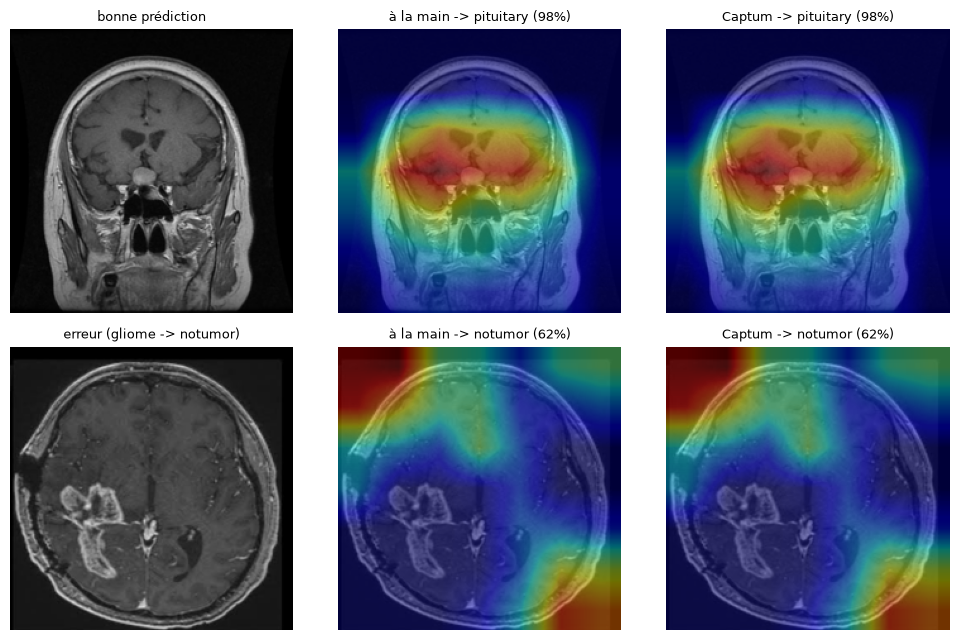

In [5]:
def show(path, ax_row, title):
    """Affiche l'IRM, puis la carte à la main et la carte Captum superposées."""
    x, display = load_image(path, config)
    k, p = predict_one(model, x)
    maps = {"à la main": gradcam_manual(model, x, k), "Captum": gradcam_captum(model, x, k)}
    ax_row[0].imshow(display)
    ax_row[0].set_title(title, fontsize=9)
    for ax, (name, m) in zip(ax_row[1:], maps.items(), strict=True):
        ax.imshow(display)
        ax.imshow(upsample(m, 224), cmap="jet", alpha=0.45, vmin=0, vmax=1)
        ax.set_title(f"{name} -> {class_names[k]} ({p:.0%})", fontsize=9)
    for ax in ax_row:
        ax.axis("off")


fig, axes = plt.subplots(2, 3, figsize=(10, 6.5))
show(good, axes[0], "bonne prédiction")
show(bad, axes[1], "erreur (gliome -> notumor)")
plt.tight_layout()
plt.show()

## 5. Ce qu'on retient
- À la main ou avec Captum : **même carte**. En pratique on garde Captum (moins de code, pas de hook à gérer).
- Le modèle doit être en `eval()`, sinon BatchNorm utilise les statistiques du lot et la carte change.
- La carte est **grossière** (7 x 7 agrandie) : elle montre une zone, pas un contour précis.
- Sur l'erreur, regarder si la zone chaude est sur la tumeur ou ailleurs (voir la galerie commentée dans `docs/figures/gradcam_gallery.png`).